> **Telecommunication Lab | Experiment 12 - Extended Practical**  
> **Original manual:** (2,1,2) convolutional **encoder**. Original encoder code and plots are preserved.  
> **New exam additions:** bit-error insertion, hard-decision **Viterbi decoding**, and **AWGN / Eb/N0** noise.  
> **Run:** Kernel > Restart & Run All. **Packages:** Python 3, `matplotlib`, `numpy`. No SciPy required.

# Experiment 12 — Convolutional Codes

**Aim (manual):** Implement a convolutional encoder in MATLAB. The manual specifically codes a **$(2,1,2)$ encoder**.

## 1. Theory / working principle

A **convolutional encoder** forms multiple output bits from the current input bit **and the previous stored bits**, using shift registers (delay elements) and XOR gates.

For this manual's $(n,k,m)=(2,1,2)$ encoder:

- $k=1$: one input bit enters per step.
- $n=2$: two coded output bits are produced per step.
- $m=2$: two memory (flip-flop) elements retain past bits.
- **Code rate:** $R=k/n=1/2$.
- **Constraint length:** $K=m+1=3$ (the current bit plus two previous bits).

The XOR wiring in the manual corresponds to these generator polynomials:

$$g_1(D)=1+D+D^2,\qquad g_2(D)=1+D^2$$

For the current input $u_i$ and previous stored bits $u_{i-1}$ and $u_{i-2}$:

$$c_1(i)=u_i\oplus u_{i-1}\oplus u_{i-2}$$

$$c_2(i)=u_i\oplus u_{i-2}$$

Here $\oplus$ means **XOR** (addition modulo 2): $0\oplus0=0$, $0\oplus1=1$, $1\oplus1=0$.

**Encoder flow:** current bit and shift-register bits → XOR connections → 2-bit coded output → shift the new bit into the memory.


## 2. Worked example from the manual

The manual uses the message **`1 0 1 1`**. It appends **two zeros** to flush the two memory elements back toward the zero state:

$$\text{encoder input}=1\;0\;1\;1\;0\;0$$

| Current input $u_i$ | Register ($u_{i-1}$,$u_{i-2}$) **before** step | $c_1$ | $c_2$ | Output pair |
|---:|:---:|---:|---:|:---:|
| 1 | 0,0 | 1 | 1 | `11` |
| 0 | 1,0 | 1 | 0 | `10` |
| 1 | 0,1 | 0 | 0 | `00` |
| 1 | 1,0 | 0 | 1 | `01` |
| 0 | 1,1 | 0 | 1 | `01` |
| 0 | 0,1 | 1 | 1 | `11` |

Output pairs: `11 10 00 01 01 11`  
Serialized encoded bits: **`111000010111`** (12 bits, including termination).

**Manual correspondence:** the manual prints the **code vector `c`** as six 2-bit rows. The two illustrative input/output plots here are extra visual study aids, not required manual plots. This experiment is encoder-only: the manual does **not** implement Viterbi decoding.


## 3. Original encoder - run unchanged

This is your uploaded simplified Python program. It prints six 2-bit output pairs and draws the **original input** and the **encoded stream**. The extension below adds channel errors and a decoder **without changing the encoder**.

Encoder input: [1, 0, 1, 1, 0, 0]
Output pairs: 11 10 00 01 01 11
Encoded stream: 111000010111


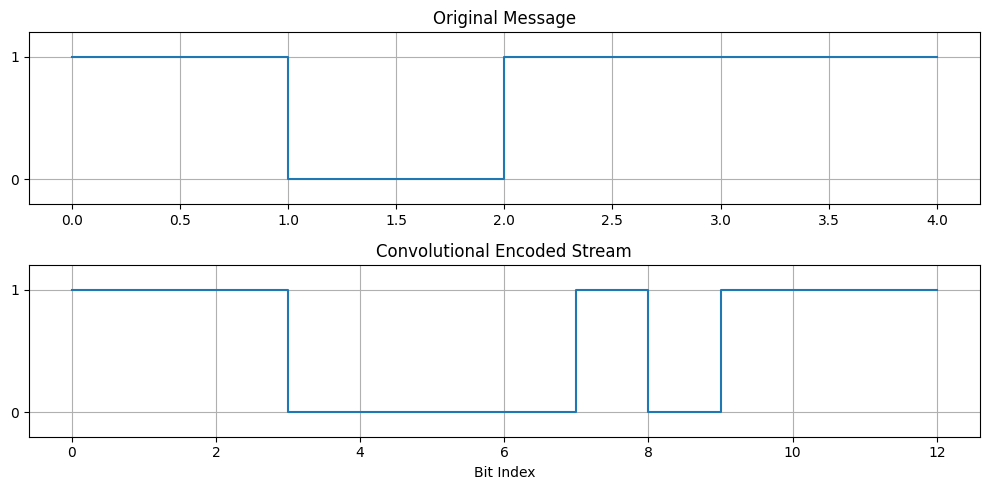

In [1]:

"""Experiment 12: (2,1,2) Convolutional Encoder."""
import matplotlib.pyplot as plt

# 1. Original Message and Two Terminating Zeros
message = [1, 0, 1, 1]
input_bits = message + [0, 0]

# 2. Initialize Two Shift Registers
d1 = d2 = 0
pairs = []

# 3. Convolutional Encoding using XOR
for bit in input_bits:
    c1 = bit ^ d1 ^ d2     # Generator g1 = 111
    c2 = bit ^ d2          # Generator g2 = 101
    pairs.append([c1, c2])
    d2, d1 = d1, bit       # Shift registers

# 4. Convert Output Pairs into Serial Bit Stream
encoded = [b for pair in pairs for b in pair]

# 5. Display Results
print("Encoder input:", input_bits)
print("Output pairs:", ' '.join(''.join(map(str, p)) for p in pairs))
print("Encoded stream:", ''.join(map(str, encoded)))

# 6. Plot Original and Encoded Signals
fig, ax = plt.subplots(2, 1, figsize=(10, 5))

ax[0].step(range(len(message)+1), message + [message[-1]], where='post')
ax[0].set_title("Original Message")

ax[1].step(range(len(encoded)+1), encoded + [encoded[-1]], where='post')
ax[1].set_title("Convolutional Encoded Stream")

for a in ax:
    a.set_ylim(-0.2, 1.2)
    a.set_yticks([0, 1])
    a.grid(True)

ax[1].set_xlabel("Bit Index")
plt.tight_layout()
plt.show()


## 4. Expected output and interpretation

- Printed **encoder input**: `[1, 0, 1, 1, 0, 0]`.
- Printed **output pairs**: `11 10 00 01 01 11`.
- Printed **encoded stream**: `111000010111`.
- Plot 1: the original four input bits; Plot 2: 12 serialized output bits.

**Result to write:** A $(2,1,2)$ convolutional encoder was implemented. For input `1011` followed by two termination zeros, it produced `11 10 00 01 01 11` using shift registers and XOR operations.

## 5. Viva — short answers

**Q1. What is convolutional coding?** Encoding each input using the current input bit and previous stored bits.  
**Q2. Code rate?** $k/n=1/2$, i.e., two output bits per one input bit.  
**Q3. What is memory order here?** $m=2$ flip-flops.  
**Q4. Constraint length?** $K=m+1=3$.  
**Q5. Why append two zeros?** To terminate/flush the encoder's two memory elements.  
**Q6. What is XOR?** Output `1` if an odd number of inputs are `1`.  
**Q7. What are the generators?** $g_1=111$, $g_2=101$ (binary tap patterns).  
**Q8. How many coded bits result?** Six processed inputs $\times$ two output bits = **12** encoded bits.  
**Q9. What decoder is commonly associated with convolutional codes?** Viterbi decoding; it is **not present** in the manual; implemented in the *new sections below*.

**Practice:** Derive the first 3 output pairs from the XOR equations before running the cell.


---
## 6. NEW - Bit errors, Viterbi decoding, and error detection

**Why this was added:** The original lab manual teaches **convolutional encoding only**. Your teacher may also ask you to add errors, show how a decoder recovers the message, and use a signal-to-noise measure. These are **exam extensions**, not part of the manual's original program.

**Communication flow:** `Message -> Convolutional Encoder -> Noisy Channel -> Received Bits -> Viterbi Decoder -> Estimated Message`

- **Error insertion:** deliberately flip one coded bit using `received[position] ^= 1`.
- **Hard-decision Viterbi:** assumes each received channel symbol has been decided as a 0 or 1. For every possible input bit and shift-register state, predict an output pair and compare it with the received pair.
- **Branch metric:** Hamming distance, the number of mismatched bits in two pairs:

$$d_H(r,c)=\sum_j \mathbf{1}(r_j\ne c_j)$$

- **Path metric:** cumulative Hamming distance. At every step, retain the best (minimum-metric) path reaching each encoder state. With two registers there are $2^2=4$ possible states.
- **Known states:** start in `(d1,d2)=(0,0)`. The two final zeros force the encoder to end in `(0,0)`, so we select that state during traceback and remove the two tail bits.

**Important distinction:** In this demonstration we can **count channel errors** by comparing received bits with known transmitted bits. A real receiver generally does **not** know the transmitted bits. Viterbi gives a *most-likely* decoded message; it is **not a guaranteed error detector**. CRC is commonly added when reliable error detection is required.

In [2]:
# 7. Hard-decision Viterbi decoder (same g1=111, g2=101)
def viterbi_decode(received_bits):
    # State = (d1, d2). Each survivor stores (distance, input path).
    paths = {(0, 0): (0, [])}
    for i in range(0, len(received_bits), 2):
        rx_pair = received_bits[i:i+2]
        new_paths = {}
        for (d1, d2), (distance, path) in paths.items():
            for bit in (0, 1):
                expected = [bit ^ d1 ^ d2, bit ^ d2]
                errors = sum(a != b for a, b in zip(expected, rx_pair))
                next_state = (bit, d1)
                candidate = (distance + errors, path + [bit])
                if next_state not in new_paths or candidate[0] < new_paths[next_state][0]:
                    new_paths[next_state] = candidate
        paths = new_paths

    # The encoder ended with two tail zeros -> final state (0,0).
    full_input = paths[(0, 0)][1]
    best_distance = paths[(0, 0)][0]
    return full_input[:-2], best_distance  # remove tail zeros


Original message:  1011
Encoded stream:   111000010111
Received stream:  111100010111
Channel bit errors: 1
Viterbi path metric: 1
Decoded message:   1011
Remaining message errors: 0


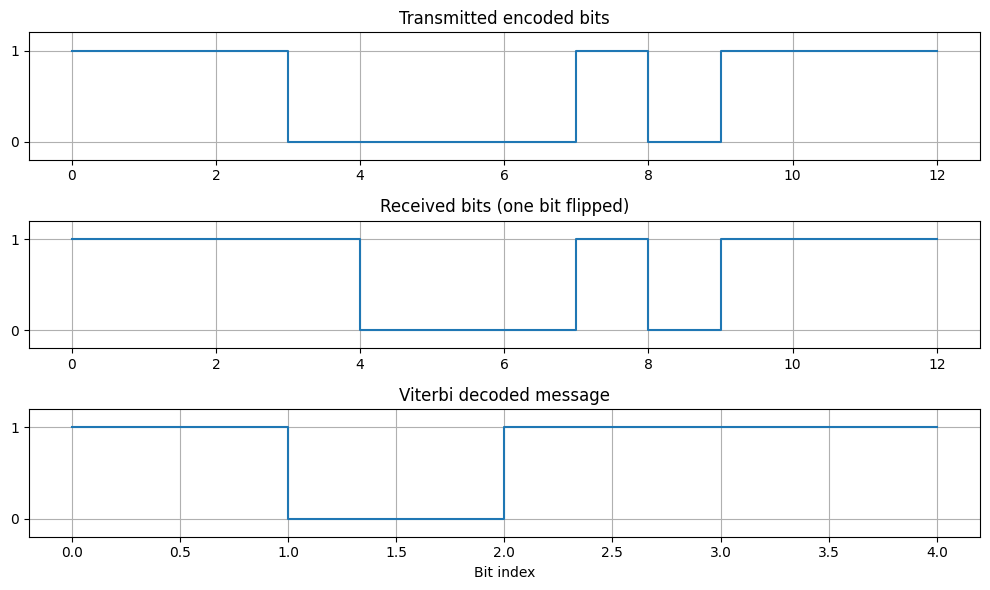

In [3]:
# 8. Example: manually corrupt one encoded bit and decode
received = encoded.copy()       # Keep original encoded stream unchanged
error_position = 3              # Zero-based index: fourth coded bit
received[error_position] ^= 1   # Flip 0 <-> 1 (XOR with 1)

decoded_message, metric = viterbi_decode(received)
channel_errors = sum(a != b for a, b in zip(encoded, received))
message_errors = sum(a != b for a, b in zip(message, decoded_message))

print("Original message: ", ''.join(map(str, message)))
print("Encoded stream:  ", ''.join(map(str, encoded)))
print("Received stream: ", ''.join(map(str, received)))
print("Channel bit errors:", channel_errors)
print("Viterbi path metric:", metric)
print("Decoded message:  ", ''.join(map(str, decoded_message)))
print("Remaining message errors:", message_errors)

fig, ax = plt.subplots(3, 1, figsize=(10, 6))
for a, values, title in zip(ax,
                            [encoded, received, decoded_message],
                            ["Transmitted encoded bits", "Received bits (one bit flipped)",
                             "Viterbi decoded message"]):
    a.step(range(len(values)+1), values+[values[-1]], where="post")
    a.set_yticks([0, 1]); a.set_ylim(-0.2, 1.2); a.grid(True)
    a.set_title(title)
ax[-1].set_xlabel("Bit index")
plt.tight_layout()
plt.show()


## 7. NEW - SNR / $E_b/N_0$ and Gaussian noise (AWGN)

In an actual radio link, the channel adds noise rather than intentionally flipping bits. We demonstrate noise by using **BPSK** to map coded bits to voltages and adding random **AWGN** (additive white Gaussian noise).

1. Transmit each coded bit as a BPSK symbol: $0\to+1$, $1\to-1$.
2. Add random noise: $y=s+n$, where $n\sim\mathcal{N}(0,\sigma^2)$.
3. Hard decision: $y<0\Rightarrow 1$, otherwise $0$.
4. Use `viterbi_decode()` to recover the original information bits.

The signal-to-noise quantity used here is **$E_b/N_0$** (information bit energy / noise power-spectral density), measured in **dB**:

$$\gamma_b=10^{(E_b/N_0)_{\rm dB}/10}, \qquad
\sigma=\sqrt{\frac{1}{2R\gamma_b}}$$

For this normalized BPSK demonstration, symbol amplitude $=1$ and **nominal code rate $R=1/2$**. The short 4-bit example also sends two tail bits, so its *effective* payload rate is lower; the formula above intentionally uses the conventional nominal rate. Increasing $E_b/N_0$ usually means less noise and fewer bit errors, **but the outcome for a short 4-bit message can vary by chance**.

**BER (bit-error rate):** $\mathrm{BER}=\dfrac{\text{incorrect bits}}{\text{total compared bits}}$.

*The original manual does not include an SNR or BER simulation. This is an extra exam demonstration.*

Eb/N0 = 2 dB; noise sigma = 0.794
Received coded bits: 111100010111
Coded-bit errors:    1 / 12
Viterbi decoded:     1011
Message-bit errors:  0 / 4


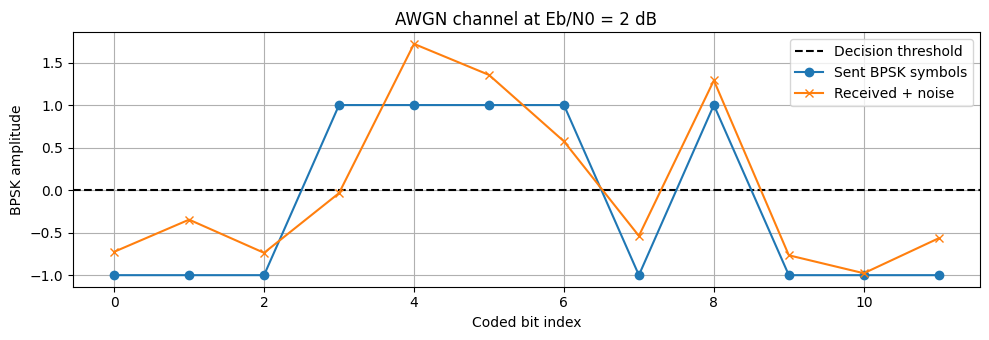

In [4]:
# 9. BPSK + AWGN channel with adjustable Eb/N0
import numpy as np

EbN0_dB = 2              # Try 0, 2, 5, or 8 dB
R = 1/2                  # Convolutional code rate
rng = np.random.default_rng(1)  # Fixed seed -> reproducible result

symbols = 1 - 2 * np.array(encoded)        # 0 -> +1, 1 -> -1
EbN0 = 10**(EbN0_dB / 10)                 # dB -> linear scale
sigma = np.sqrt(1 / (2 * R * EbN0))      # AWGN standard deviation
noisy_symbols = symbols + rng.normal(0, sigma, len(symbols))
rx_bits = (noisy_symbols < 0).astype(int).tolist()  # Hard decisions

estimated, metric = viterbi_decode(rx_bits)
raw_errors = sum(a != b for a, b in zip(encoded, rx_bits))
decoded_errors = sum(a != b for a, b in zip(message, estimated))

print(f"Eb/N0 = {EbN0_dB} dB; noise sigma = {sigma:.3f}")
print("Received coded bits:", ''.join(map(str, rx_bits)))
print("Coded-bit errors:   ", raw_errors, "/", len(encoded))
print("Viterbi decoded:    ", ''.join(map(str, estimated)))
print("Message-bit errors: ", decoded_errors, "/", len(message))

plt.figure(figsize=(10, 3.5))
plt.axhline(0, color='black', linestyle='--', label='Decision threshold')
plt.plot(range(len(symbols)), symbols, 'o-', label='Sent BPSK symbols')
plt.plot(range(len(symbols)), noisy_symbols, 'x-', label='Received + noise')
plt.xlabel('Coded bit index'); plt.ylabel('BPSK amplitude')
plt.title(f'AWGN channel at Eb/N0 = {EbN0_dB} dB')
plt.grid(True); plt.legend(); plt.tight_layout(); plt.show()


## 8. Final results, observations, and viva

### Expected outputs when you run the notebook

- **Original encoder:** `1011 -> (tail 00) -> 11 10 00 01 01 11` (serial: `111000010111`).
- **Manual error experiment:** flip the *fourth encoded bit*: received `111100010111`; Viterbi recovers `1011` and reports **0 remaining message errors**.
- **SNR experiment:** with `EbN0_dB = 2` and random seed `1`, the hard-decision channel flips **one coded bit**, but Viterbi still recovers `1011`.
- **Plots:** original and coded binary waveforms; original vs corrupted coded bits vs decoded message; BPSK symbol voltages before/after AWGN.

### Quick viva questions

| Question | Short answer |
|---|---|
| What does convolutional coding do? | Adds structured redundancy so a decoder can correct some errors. |
| What is the code rate? | $R=1/2$: two encoded bits per input bit, before considering tail overhead. |
| What are the generator connections? | $g_1=111$ and $g_2=101$. |
| What does Viterbi do? | Finds the most likely state/input sequence using a minimum path metric. |
| What is Hamming distance? | The number of bit positions where two binary sequences differ. |
| Does Viterbi always correct errors? | No. Heavy noise can cause incorrect decoding. |
| Is SNR the same as $E_b/N_0$? | Not exactly; $E_b/N_0$ normalizes noise against bit energy. |
| What happens when $E_b/N_0$ increases? | Normally fewer hard-decision errors and lower BER. |
| Can a decoder detect every error by itself? | Not guaranteed; add CRC for more reliable error detection. |
| Why append two zeros? | To return the encoder to known state `(0,0)` for terminated decoding. |

**One-sentence exam conclusion:** A rate-1/2 convolutional encoder was implemented using two shift registers; under single-bit corruption and a sample AWGN channel, hard-decision Viterbi decoding recovered the original message.